<a href="https://colab.research.google.com/github/makkawaruahmadimanuddin-rgb/Data-Science-PRT2/blob/main/Visualisasi_Makkawaru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

VISUALISASI DATA GORONTALO

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Membaca dataset
df = pd.read_csv('dataset_fiskal_97_hipoFull.csv')

# 2. Filter data khusus Kota Gorontalo dan urutkan berdasarkan tahun
df_gorontalo = (
    df[df['Kota'] == 'Kota Gorontalo'].sort_values('Tahun').reset_index(drop=True)
)

# Pengaturan gaya tampilan grafik
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

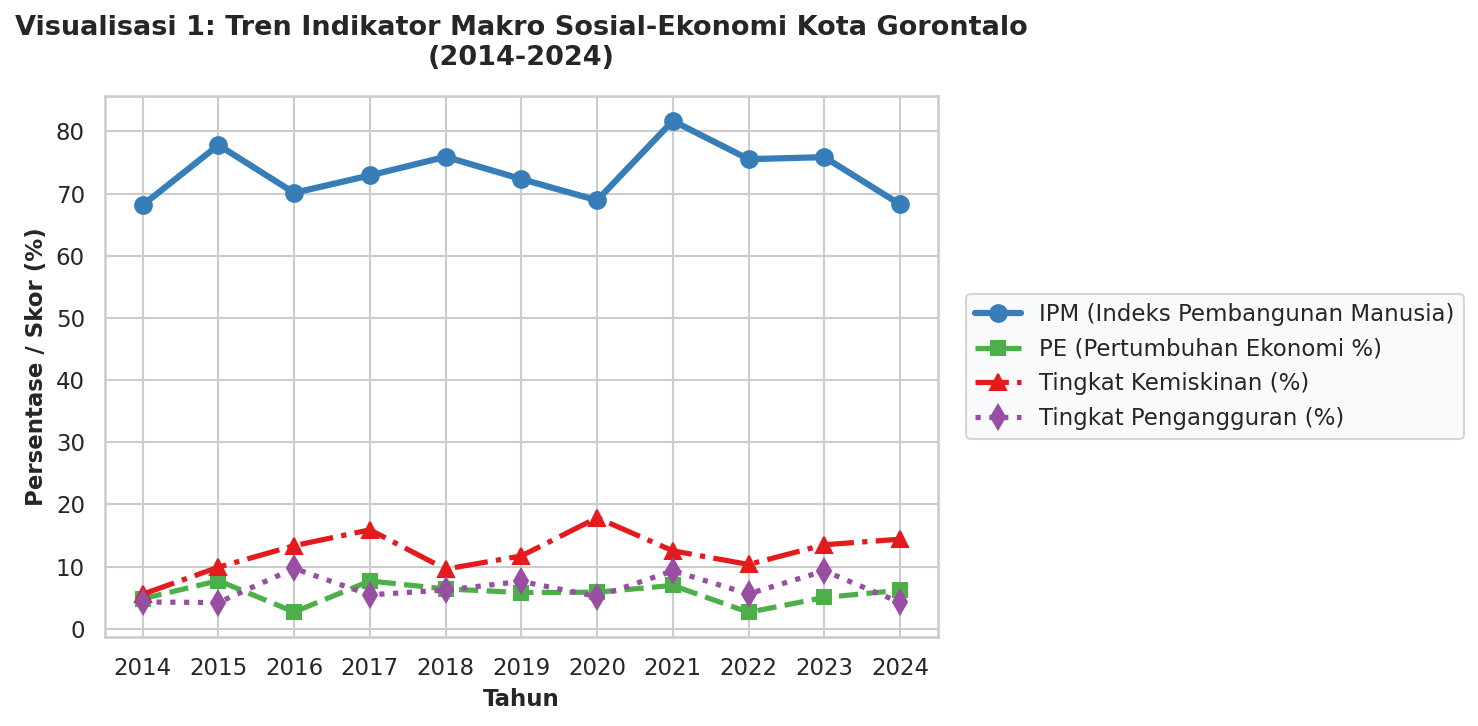

In [ ]:
# VISUALISASI 1: Tren Indikator Makro Sosial-Ekonomi

fig, ax1 = plt.subplots(figsize=(10, 5))

# Menggunakan palet warna 'Set1' yang lebih tajam dan modern
colors = sns.color_palette('Set1', 4)

ax1.set_xlabel('Tahun', fontsize=11, fontweight='bold', family='sans-serif')
ax1.set_ylabel('Persentase / Skor (%)', fontsize=11, fontweight='bold', family='sans-serif')

l1 = ax1.plot(
    df_gorontalo['Tahun'],
    df_gorontalo['IPM'],
    marker='o',
    markersize=8,
    linewidth=3.0,
    color=colors[1],
    label='IPM (Indeks Pembangunan Manusia)',
)[0]
l2 = ax1.plot(
    df_gorontalo['Tahun'],
    df_gorontalo['PE'],
    marker='s',
    markersize=7,
    linewidth=2.5,
    linestyle='--',
    color=colors[2],
    label='PE (Pertumbuhan Ekonomi %)',
)[0]
l3 = ax1.plot(
    df_gorontalo['Tahun'],
    df_gorontalo['KEMISKINAN'],
    marker='^',
    markersize=8,
    linewidth=2.5,
    linestyle='-.',
    color=colors[0],
    label='Tingkat Kemiskinan (%)',
)[0]
l4 = ax1.plot(
    df_gorontalo['Tahun'],
    df_gorontalo['PENGANGGURAN'],
    marker='d',
    markersize=8,
    linewidth=2.5,
    linestyle=':',
    color=colors[3],
    label='Tingkat Pengangguran (%)',
)[0]

ax1.set_xticks(df_gorontalo['Tahun'])
ax1.set_title(
    'Visualisasi 1: Tren Indikator Makro Sosial-Ekonomi Kota Gorontalo\n(2014-2024)',
    fontsize=13,
    fontweight='bold',
    pad=15,
    family='sans-serif'
)
ax1.legend(
    handles=[l1, l2, l3, l4],
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    facecolor='#f8f9fa'
)
plt.tight_layout()
plt.savefig('visualisasi_1_indikator_makro.png', bbox_inches='tight')
plt.show()

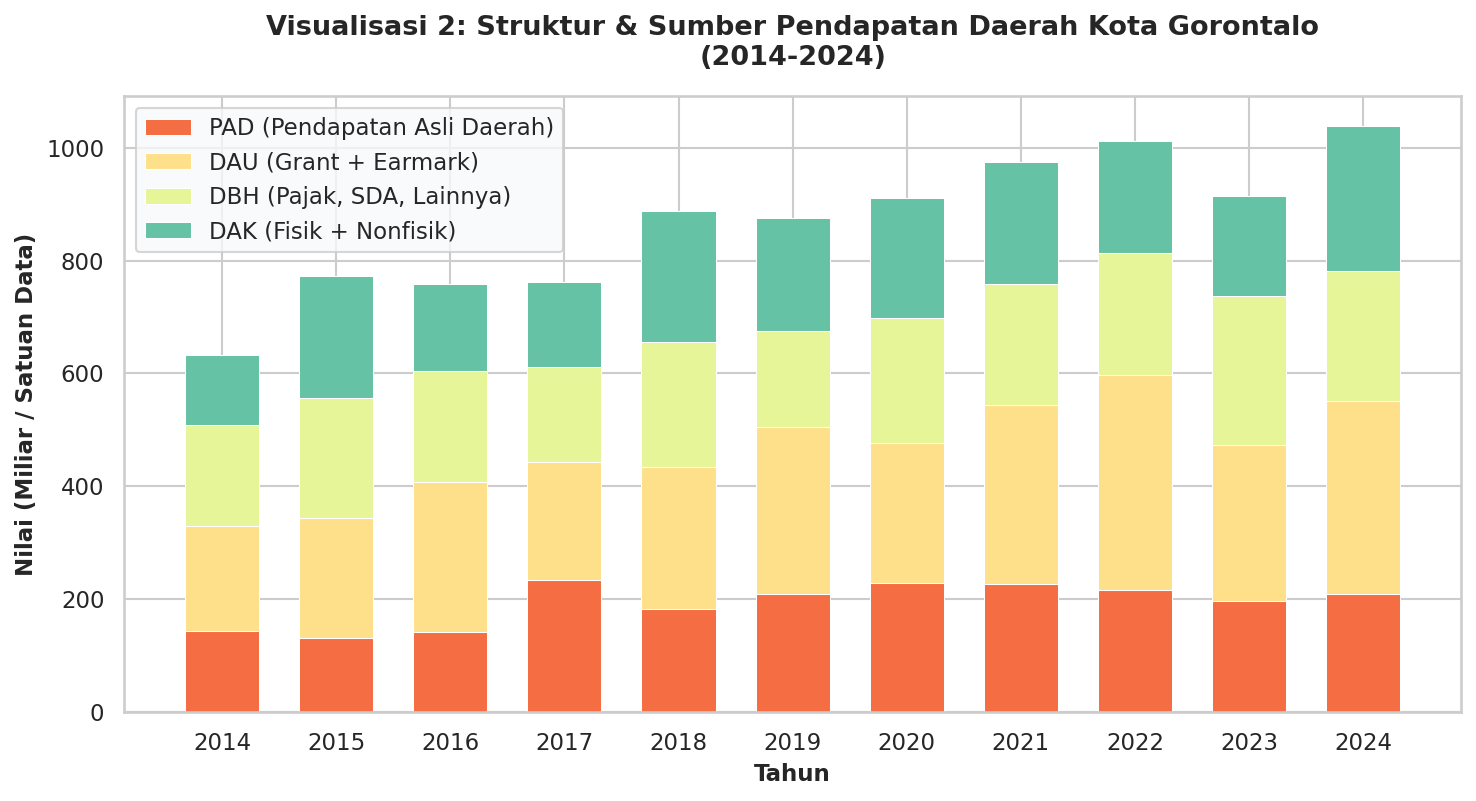

In [ ]:
# VISUALISASI 2: Struktur & Sumber Pendapatan Daerah

df_gorontalo['Total_DBH'] = (
    df_gorontalo['DBH_PAJAK'] + df_gorontalo['DBH_SDA'] + df_gorontalo['DBH_Lainnya']
)
df_gorontalo['Total_DAU'] = df_gorontalo['DAU_Grant'] + df_gorontalo['DAU_Earmark']
df_gorontalo['Total_DAK'] = df_gorontalo['DAK_Fisik'] + df_gorontalo['DAK_Nonfisik']

fig, ax = plt.subplots(figsize=(10, 5.5))
years = df_gorontalo['Tahun']
bar_width = 0.65

# Menggunakan palet warna 'Spectral' yang lebih bergradasi dan elegan
colors = sns.color_palette('Spectral', 4)

p1 = ax.bar(
    years,
    df_gorontalo['PAD'],
    bar_width,
    label='PAD (Pendapatan Asli Daerah)',
    color=colors[0],
    edgecolor='white',
    linewidth=0.5
)
p2 = ax.bar(
    years,
    df_gorontalo['Total_DAU'],
    bar_width,
    bottom=df_gorontalo['PAD'],
    label='DAU (Grant + Earmark)',
    color=colors[1],
    edgecolor='white',
    linewidth=0.5
)
p3 = ax.bar(
    years,
    df_gorontalo['Total_DBH'],
    bar_width,
    bottom=df_gorontalo['PAD'] + df_gorontalo['Total_DAU'],
    label='DBH (Pajak, SDA, Lainnya)',
    color=colors[2],
    edgecolor='white',
    linewidth=0.5
)
p4 = ax.bar(
    years,
    df_gorontalo['Total_DAK'],
    bar_width,
    bottom=df_gorontalo['PAD']
    + df_gorontalo['Total_DAU']
    + df_gorontalo['Total_DBH'],
    label='DAK (Fisik + Nonfisik)',
    color=colors[3],
    edgecolor='white',
    linewidth=0.5
)

ax.set_xlabel('Tahun', fontsize=11, fontweight='bold', family='sans-serif')
ax.set_ylabel('Nilai (Miliar / Satuan Data)', fontsize=11, fontweight='bold', family='sans-serif')
ax.set_xticks(years)
ax.set_title(
    'Visualisasi 2: Struktur & Sumber Pendapatan Daerah Kota Gorontalo\n(2014-2024)',
    fontsize=13,
    fontweight='bold',
    pad=15,
    family='sans-serif'
)
ax.legend(loc='upper left', frameon=True, facecolor='#f8f9fa')
plt.tight_layout()
plt.savefig('visualisasi_2_pendapatan.png', bbox_inches='tight')
plt.show()

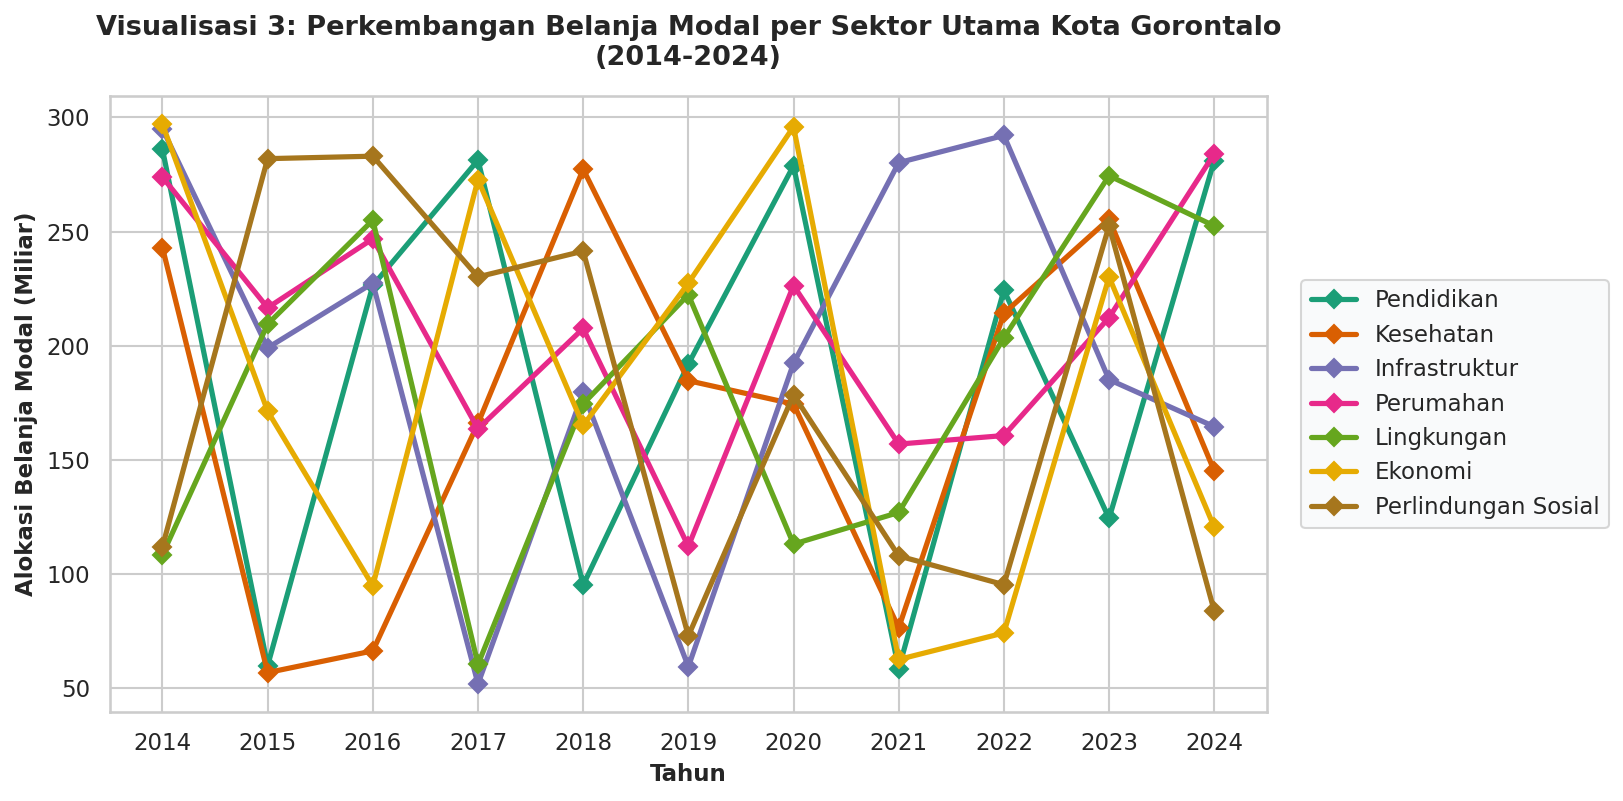

In [ ]:
# VISUALISASI 3: Perkembangan Belanja Modal per Sektor Utama

fig, ax = plt.subplots(figsize=(11, 5.5))

sektor_cols = {
    'bm_pendidikan': 'Pendidikan',
    'bm_kesehatan': 'Kesehatan',
    'bm_infrastruktur': 'Infrastruktur',
    'bm_perumahan': 'Perumahan',
    'bm_lingkungan': 'Lingkungan',
    'bm_ekonomi': 'Ekonomi',
    'bm_perlindungan_sosial': 'Perlindungan Sosial',
}

# Menggunakan palet warna 'Dark2' agar terlihat berbeda dari grafik sebelumnya
colors = sns.color_palette('Dark2', len(sektor_cols))

for (col, label_name), color in zip(sektor_cols.items(), colors):
  ax.plot(
      df_gorontalo['Tahun'],
      df_gorontalo[col],
      marker='D', # Mengubah marker menjadi Diamond
      linewidth=2.5,
      label=label_name,
      color=color,
  )

ax.set_xlabel('Tahun', fontsize=11, fontweight='bold', family='sans-serif')
ax.set_ylabel('Alokasi Belanja Modal (Miliar)', fontsize=11, fontweight='bold', family='sans-serif')
ax.set_xticks(df_gorontalo['Tahun'])
ax.set_title(
    'Visualisasi 3: Perkembangan Belanja Modal per Sektor Utama Kota Gorontalo\n(2014-2024)',
    fontsize=13,
    fontweight='bold',
    pad=15,
    family='sans-serif'
)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, facecolor='#f8f9fa')
plt.tight_layout()
plt.savefig('visualisasi_3_belanja_modal.png', bbox_inches='tight')
plt.show()

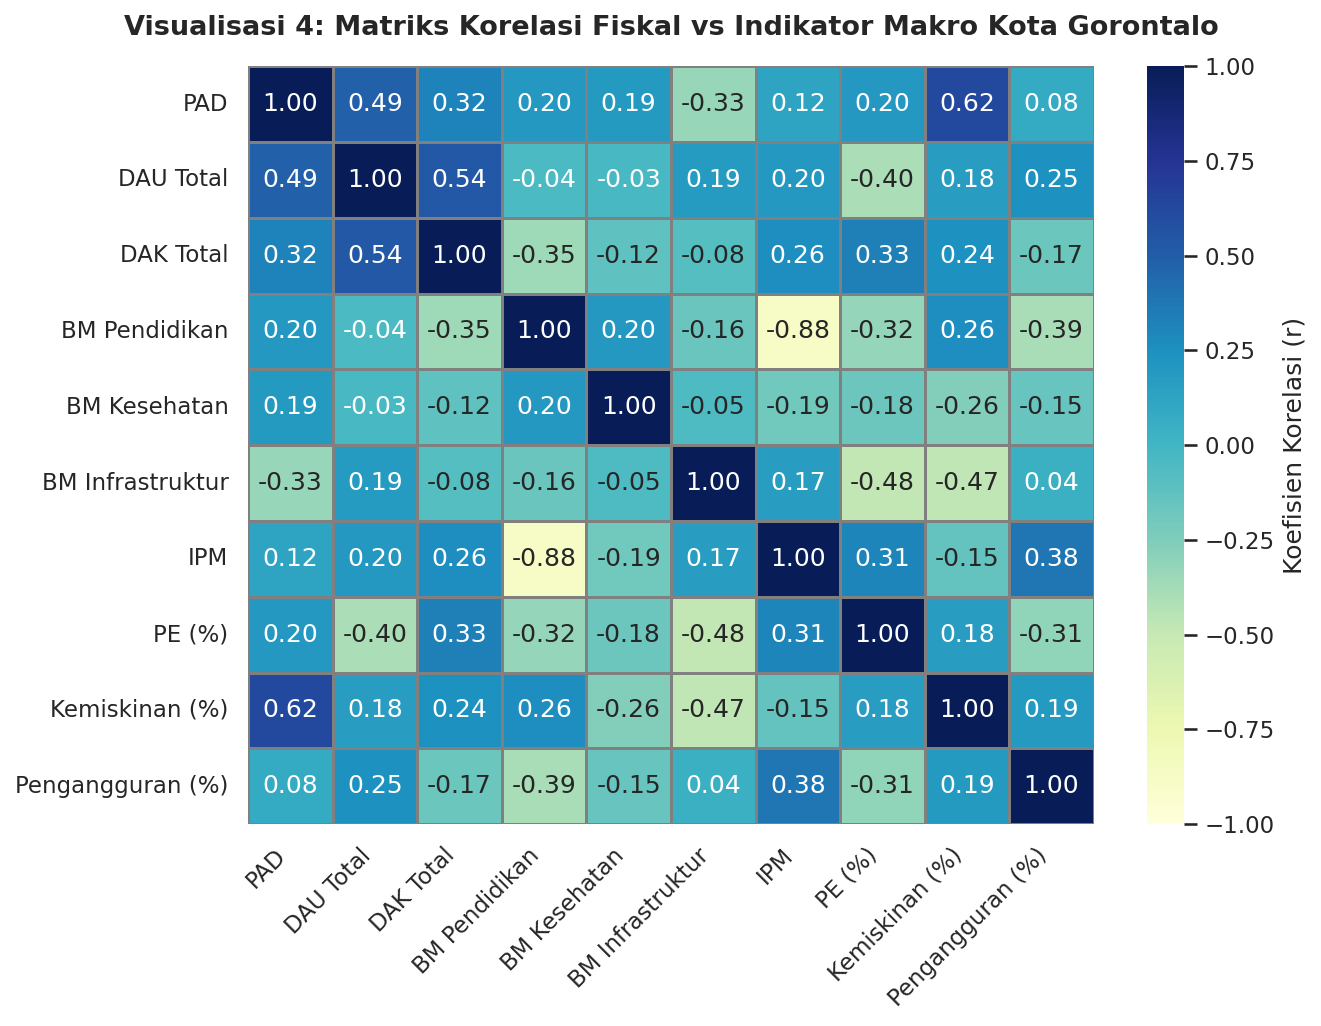

In [ ]:
# VISUALISASI 4: Matriks Korelasi Fiskal vs Indikator Makro

fig, ax = plt.subplots(figsize=(9, 7))

corr_cols = [
    'PAD',
    'Total_DAU',
    'Total_DAK',
    'bm_pendidikan',
    'bm_kesehatan',
    'bm_infrastruktur',
    'IPM',
    'PE',
    'KEMISKINAN',
    'PENGANGGURAN',
]
labels_clean = [
    'PAD',
    'DAU Total',
    'DAK Total',
    'BM Pendidikan',
    'BM Kesehatan',
    'BM Infrastruktur',
    'IPM',
    'PE (%)',
    'Kemiskinan (%)',
    'Pengangguran (%)',
]

corr_matrix = df_gorontalo[corr_cols].corr()

# Mengubah warna colormap menjadi 'YlGnBu' untuk tampilan yang berbeda
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=-1,
    vmax=1,
    xticklabels=labels_clean,
    yticklabels=labels_clean,
    ax=ax,
    cbar_kws={'label': 'Koefisien Korelasi (r)'},
    linewidths=0.5,
    linecolor='gray'
)

ax.set_title(
    'Visualisasi 4: Matriks Korelasi Fiskal vs Indikator Makro Kota Gorontalo',
    fontsize=13,
    fontweight='bold',
    pad=15,
    family='sans-serif'
)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('visualisasi_4_korelasi.png', bbox_inches='tight')
plt.show()